# Task 1 — Retail Sales Data Analysis & Business Insights

QSkill Internship | Domain: Data Science | Slab 1: Beginners

## 1. Objective
Analyze retail transactions, clean data, explore sales/profit/customer patterns, and summarize actionable business insights. The included dataset is synthetic and generated reproducibly so the notebook runs without external downloads.

In [8]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

In [9]:
rng = np.random.default_rng(RANDOM_STATE)
n = 1200
dates = pd.date_range("2024-01-01", "2025-12-31", periods=n)
categories = ["Technology", "Furniture", "Office Supplies"]
products = {
    "Technology": ["Laptop", "Monitor", "Keyboard", "Mouse"],
    "Furniture": ["Desk", "Chair", "Bookshelf", "Cabinet"],
    "Office Supplies": ["Notebook", "Pen Set", "Paper", "Stapler"]
}
category = rng.choice(categories, n, p=[0.32, 0.28, 0.40])
product = [rng.choice(products[c]) for c in category]
unit_price = np.array([{"Laptop":850,"Monitor":220,"Keyboard":35,"Mouse":20,"Desk":180,"Chair":120,
                        "Bookshelf":140,"Cabinet":160,"Notebook":5,"Pen Set":8,"Paper":7,"Stapler":12}[p] for p in product], dtype=float)
quantity = rng.integers(1, 11, n)
discount = rng.choice([0, .05, .10, .15, .20], n, p=[.35,.15,.25,.15,.10])
sales = unit_price * quantity * (1-discount)
cost_rate = rng.uniform(.55,.82,n)
profit = sales * (1-cost_rate) - sales*discount*.25
regions = rng.choice(["North","South","East","West","Central"], n)
customer_ids = rng.integers(1001, 1251, n)
df = pd.DataFrame({"Order_ID":[f"ORD{i:05d}" for i in range(n)], "Order_Date":dates,
                   "Customer_ID":customer_ids, "Region":regions, "Category":category,
                   "Product":product, "Quantity":quantity, "Unit_Price":unit_price,
                   "Discount":discount, "Sales":sales.round(2), "Profit":profit.round(2)})
# Introduce a few realistic data-quality issues for cleaning demonstration
df.loc[12, "Region"] = None
df.loc[20, "Quantity"] = np.nan
df = pd.concat([df, df.iloc[[5, 15]]], ignore_index=True)
df.head()

,Order_ID,Order_Date,Customer_ID,Region,Category,Product,Quantity,Unit_Price,Discount,Sales,Profit
0,ORD00000,2024-01-01 00:00:00.000000000,1130,East,Office Supplies,Notebook,5.0,5.0,0.10,22.50,7.82
1,ORD00001,2024-01-01 14:36:43.836530442,1171,East,Furniture,Bookshelf,7.0,140.0,0.15,833.00,314.37
2,ORD00002,2024-01-02 05:13:27.673060884,1065,North,Office Supplies,Paper,2.0,7.0,0.15,11.90,3.30
3,ORD00003,2024-01-02 19:50:11.509591326,1051,South,Office Supplies,Paper,7.0,7.0,0.15,41.65,14.71
4,ORD00004,2024-01-03 10:26:55.346121768,1157,East,Technology,Monitor,10.0,220.0,0.15,1870.00,299.02


## 2. Data understanding and cleaning

In [10]:
print("Shape before cleaning:", df.shape)
display(df.info())
display(df.describe(include="all").T)
print("Missing values:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().copy()
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")
for col in ["Quantity", "Unit_Price", "Discount", "Sales", "Profit"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["Quantity"] = df["Quantity"].fillna(df["Quantity"].median())
df["Region"] = df["Region"].fillna(df["Region"].mode()[0])
df = df.dropna(subset=["Order_Date", "Sales", "Profit"])
df = df[(df["Quantity"] > 0) & (df["Sales"] >= 0)]
df["Month"] = df["Order_Date"].dt.to_period("M").astype(str)
print("Shape after cleaning:", df.shape)
print("Remaining missing values:", int(df.isna().sum().sum()))

Shape before cleaning: (1202, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1202 entries, 0 to 1201
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Order_ID     1202 non-null   object        
 1   Order_Date   1202 non-null   datetime64[ns]
 2   Customer_ID  1202 non-null   int64         
 3   Region       1201 non-null   object        
 4   Category     1202 non-null   object        
 5   Product      1202 non-null   object        
 6   Quantity     1201 non-null   float64       
 7   Unit_Price   1202 non-null   float64       
 8   Discount     1202 non-null   float64       
 9   Sales        1202 non-null   float64       
 10  Profit       1202 non-null   float64       
dtypes: datetime64[ns](1), float64(5), int64(1), object(4)
memory usage: 103.4+ KB


None

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Order_ID,1202,1200,ORD00005,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_Date,1202,NaN,NaN,NaN,2024-12-30 09:40:02.726065408,2024-01-01 00:00:00,2024-06-30 14:04:54.245204480,2024-12-30 09:23:16.163469312,2025-07-01 04:41:38.081734656,2025-12-31 00:00:00,NaN
Customer_ID,1202.0,NaN,NaN,NaN,1126.539933,1001.0,1064.25,1130.0,1187.75,1250.0,71.545602
Region,1201,5,South,264,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,1202,3,Office Supplies,486,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product,1202,12,Notebook,137,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,1201.0,NaN,NaN,NaN,5.364696,1.0,3.0,5.0,8.0,10.0,2.879563
Unit_Price,1202.0,NaN,NaN,NaN,139.047421,5.0,8.0,35.0,160.0,850.0,229.330961
Discount,1202.0,NaN,NaN,NaN,0.076248,0.0,0.0,0.1,0.15,0.2,0.068159
Sales,1202.0,NaN,NaN,NaN,684.578245,4.0,40.0,133.0,800.0,8500.0,1364.154844


Missing values:
 Order_ID       0
Order_Date     0
Customer_ID    0
Region         1
Category       0
Product        0
Quantity       1
Unit_Price     0
Discount       0
Sales          0
Profit         0
dtype: int64
Duplicate rows: 2
Shape after cleaning: (1200, 12)
Remaining missing values: 0


## 3. Exploratory data analysis

In [11]:
print(f"Total sales: ₹{df['Sales'].sum():,.2f}")
print(f"Total profit: ₹{df['Profit'].sum():,.2f}")
print(f"Total quantity sold: {df['Quantity'].sum():,.0f}")
print(f"Unique customers: {df['Customer_ID'].nunique():,}")
print(f"Average order value: ₹{df['Sales'].mean():,.2f}")
print(f"Profit margin: {df['Profit'].sum()/df['Sales'].sum():.1%}")
display(df.groupby("Category").agg(Orders=("Order_ID","count"), Sales=("Sales","sum"), Profit=("Profit","sum"), Quantity=("Quantity","sum")).sort_values("Sales", ascending=False).round(2))
display(df.groupby("Region").agg(Sales=("Sales","sum"), Profit=("Profit","sum"), Customers=("Customer_ID","nunique")).sort_values("Sales", ascending=False).round(2))
display(df.groupby("Product").agg(Sales=("Sales","sum"), Profit=("Profit","sum"), Units=("Quantity","sum")).sort_values("Sales", ascending=False).head(10).round(2))

Total sales: ₹821,739.05
Total profit: ₹241,600.22
Total quantity sold: 6,441
Unique customers: 246
Average order value: ₹684.78
Profit margin: 29.4%


,Orders,Sales,Profit,Quantity
Category,,,,
Technology,394,561979.00,164958.13,2058.0
Furniture,321,239941.00,70578.12,1720.0
Office Supplies,485,19819.05,6063.97,2663.0


,Sales,Profit,Customers
Region,,,
West,178622.15,49364.19,162
South,175030.65,53124.61,157
East,174399.85,51886.85,159
Central,149769.20,48408.57,149
North,143917.20,38816.00,142


,Sales,Profit,Units
Product,,,
Laptop,428867.5,124715.21,548.0
Monitor,109362.0,32966.95,541.0
Cabinet,73424.0,21332.38,494.0
Desk,65682.0,20522.21,388.0
Bookshelf,54845.0,15103.73,426.0
Chair,45990.0,13619.80,412.0
Keyboard,13317.5,4034.91,409.0
Mouse,10432.0,3241.06,560.0
Stapler,8046.0,2430.44,721.0


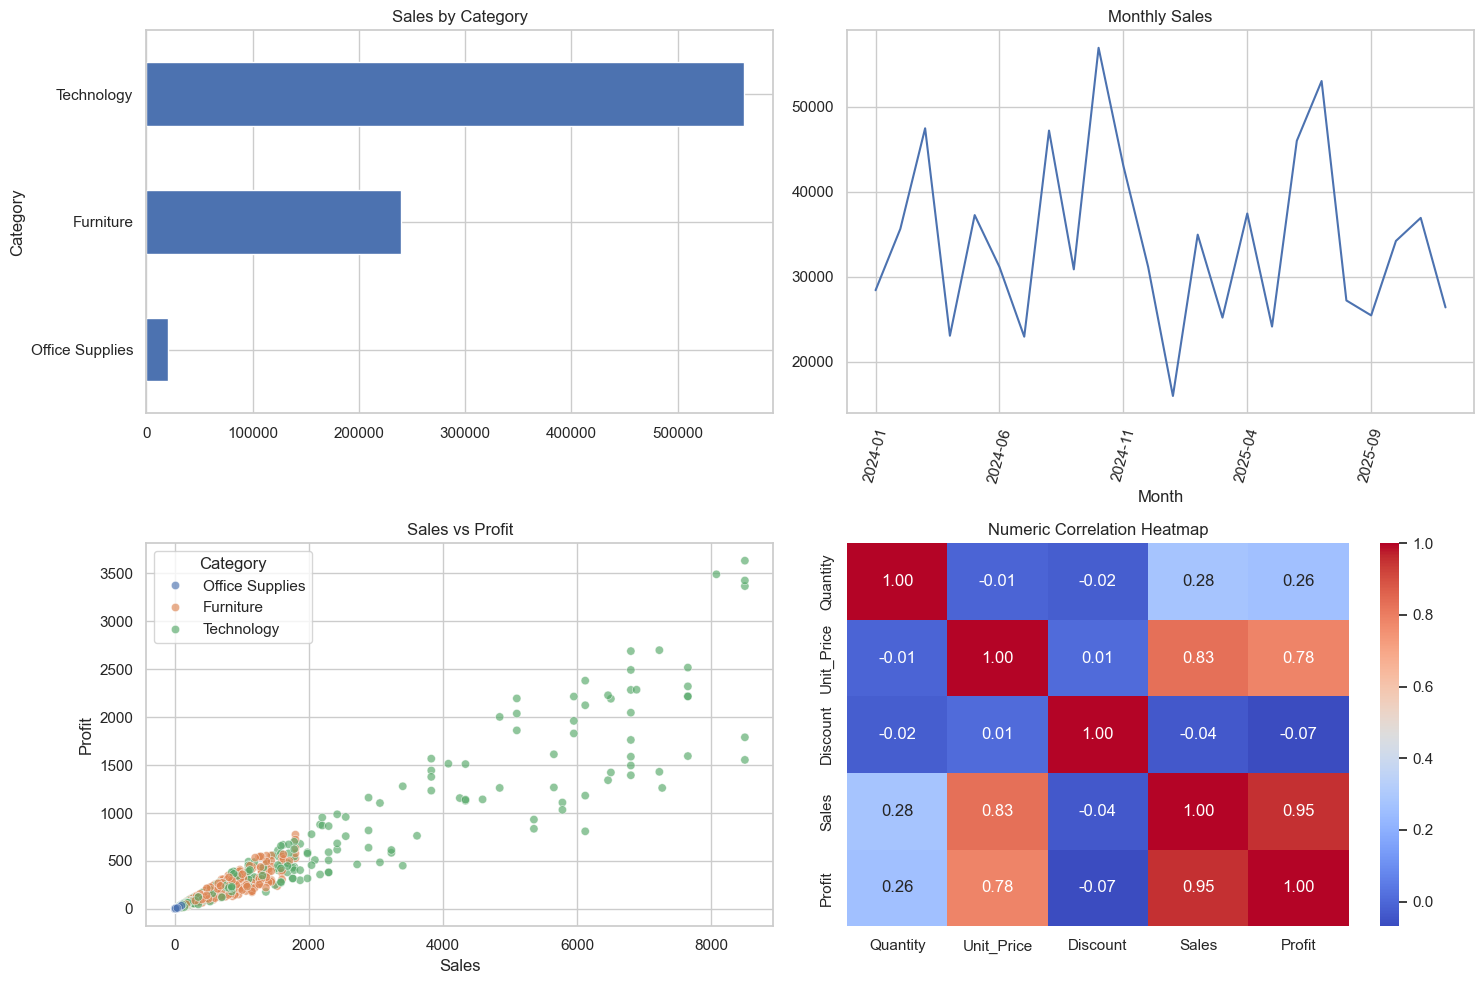

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
df.groupby("Category")["Sales"].sum().sort_values().plot(kind="barh", ax=axes[0,0], title="Sales by Category")
df.groupby("Month")["Sales"].sum().plot(ax=axes[0,1], title="Monthly Sales")
axes[0,1].tick_params(axis="x", rotation=75)
sns.scatterplot(data=df, x="Sales", y="Profit", hue="Category", alpha=.65, ax=axes[1,0])
axes[1,0].set_title("Sales vs Profit")
sns.heatmap(df[["Quantity","Unit_Price","Discount","Sales","Profit"]].corr(), annot=True, cmap="coolwarm", fmt=".2f", ax=axes[1,1])
axes[1,1].set_title("Numeric Correlation Heatmap")
plt.tight_layout()
plt.show()

## 4. Customer and regional analysis

In [13]:
customer_summary = df.groupby("Customer_ID").agg(Orders=("Order_ID","count"), Total_Sales=("Sales","sum"), Total_Profit=("Profit","sum")).sort_values("Total_Sales", ascending=False)
display(customer_summary.head(10).round(2))
region_summary = df.groupby("Region").agg(Sales=("Sales","sum"), Profit=("Profit","sum"))
region_summary["Profit_Margin"] = region_summary["Profit"] / region_summary["Sales"]
display(region_summary.sort_values("Sales", ascending=False).round(3))

,Orders,Total_Sales,Total_Profit
Customer_ID,,,
1072,7,17418.10,3856.45
1043,6,15659.15,4379.98
1228,6,15061.85,3523.20
1190,6,12127.00,3392.84
1171,8,11878.50,4410.29
1140,5,11133.20,2295.42
1008,6,11100.50,3093.39
1156,9,10786.60,2577.82
1177,5,10593.00,2531.44


,Sales,Profit,Profit_Margin
Region,,,
West,178622.15,49364.19,0.276
South,175030.65,53124.61,0.304
East,174399.85,51886.85,0.298
Central,149769.20,48408.57,0.323
North,143917.20,38816.00,0.270


## 5. Business insights and conclusion
Use the printed tables and charts to complete the observations below with your actual results.

In [14]:
top_category = df.groupby("Category")["Sales"].sum().idxmax()
top_region = df.groupby("Region")["Sales"].sum().idxmax()
top_product = df.groupby("Product")["Sales"].sum().idxmax()
best_profit_region = df.groupby("Region")["Profit"].sum().idxmax()
print(f"• Highest-revenue category: {top_category}. Prioritize stock availability and targeted campaigns for this category.")
print(f"• Highest-revenue region: {top_region}. Review this region's successful channels and test whether they can be replicated elsewhere.")
print(f"• Top product by sales: {top_product}. Monitor its inventory and contribution to profit.")
print(f"• Highest total-profit region: {best_profit_region}. Compare its discounting and product mix with lower-performing regions.")
print("• Check the monthly trend chart for seasonal peaks and plan inventory and promotions accordingly.")
print("• Review the sales-profit scatter plot for high-sales orders with low or negative profit; discount and cost policies may need attention.")

• Highest-revenue category: Technology. Prioritize stock availability and targeted campaigns for this category.
• Highest-revenue region: West. Review this region's successful channels and test whether they can be replicated elsewhere.
• Top product by sales: Laptop. Monitor its inventory and contribution to profit.
• Highest total-profit region: South. Compare its discounting and product mix with lower-performing regions.
• Check the monthly trend chart for seasonal peaks and plan inventory and promotions accordingly.
• Review the sales-profit scatter plot for high-sales orders with low or negative profit; discount and cost policies may need attention.
